### In this notebook I tried a different approach with combining the datasets and did some EDA with the whole set

In [56]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [57]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")

dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie1.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    # "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

In [58]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,Speed_kmh,Frostbumps,run_id,road_id
0,45493158.5,3850.503,106.794000,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,62.1936,0,A1,A
1,45493161.0,3850.546,106.794000,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,62.2044,0,A1,A
2,45493163.5,3850.589,106.794000,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,62.2116,0,A1,A
3,45493166.0,3850.633,106.794000,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,62.2224,0,A1,A
4,45493168.5,3850.676,106.794000,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,62.2332,0,A1,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
300812,41563778.5,5512.852,10.355333,0.6512,-1.5795,-48.0806,-1.78920,0.16438,10.33153,-0.00936,-0.01235,-0.02487,33.9372,0,B4,B
300813,41563781.0,5512.875,11.012904,0.6481,-1.5840,-47.9881,-1.88369,-0.02342,10.76440,-0.00575,-0.00767,-0.02849,33.9372,0,B4,B
300814,41563783.5,5512.899,10.800525,0.6452,-1.5904,-47.8951,-1.92509,-0.06587,10.62556,-0.00451,-0.02198,-0.02490,33.9372,0,B4,B
300815,41563786.0,5512.922,10.374600,0.6427,-1.5977,-47.8027,-1.60182,0.24200,10.34438,-0.00214,-0.02739,-0.02887,33.9408,0,B4,B


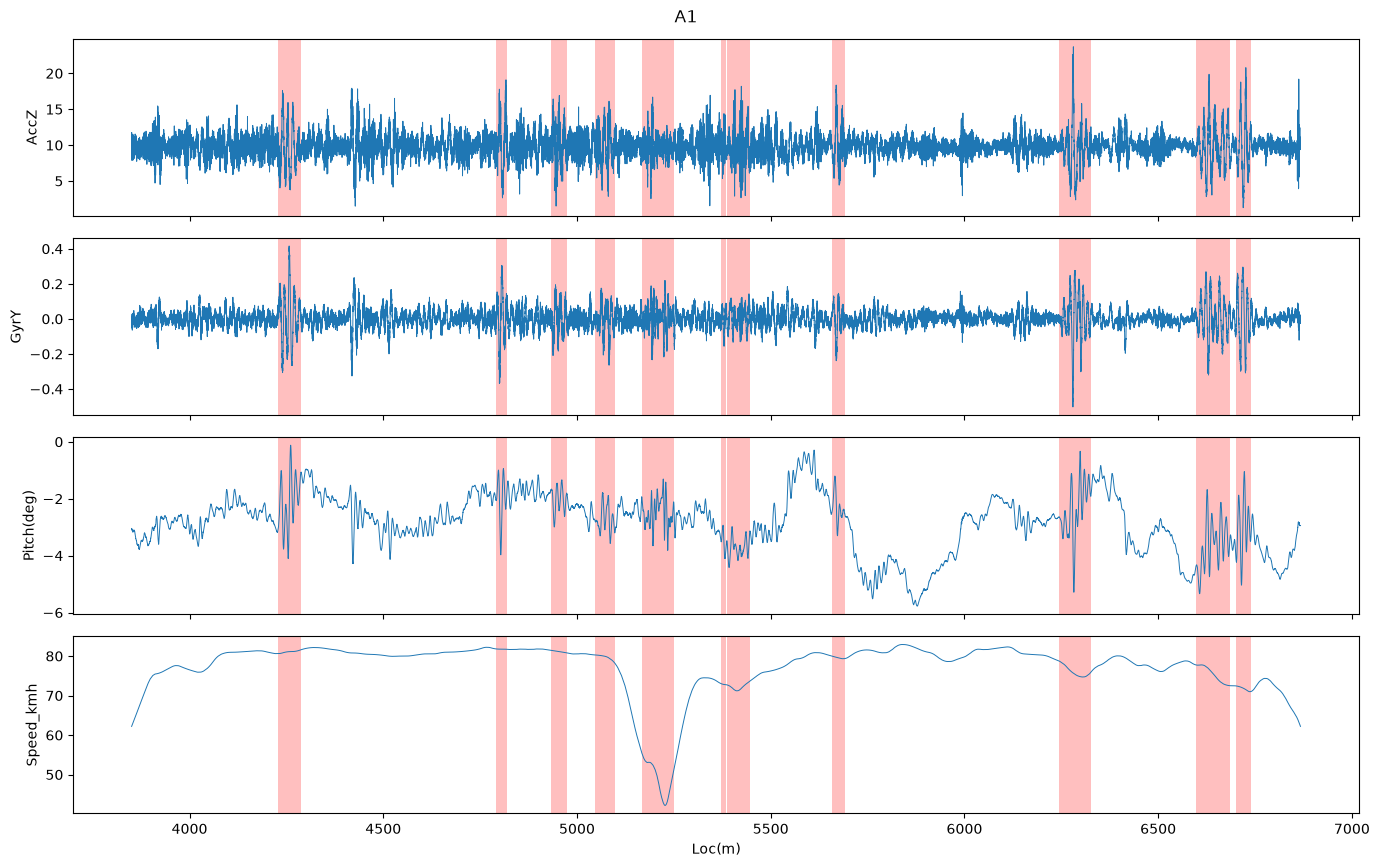

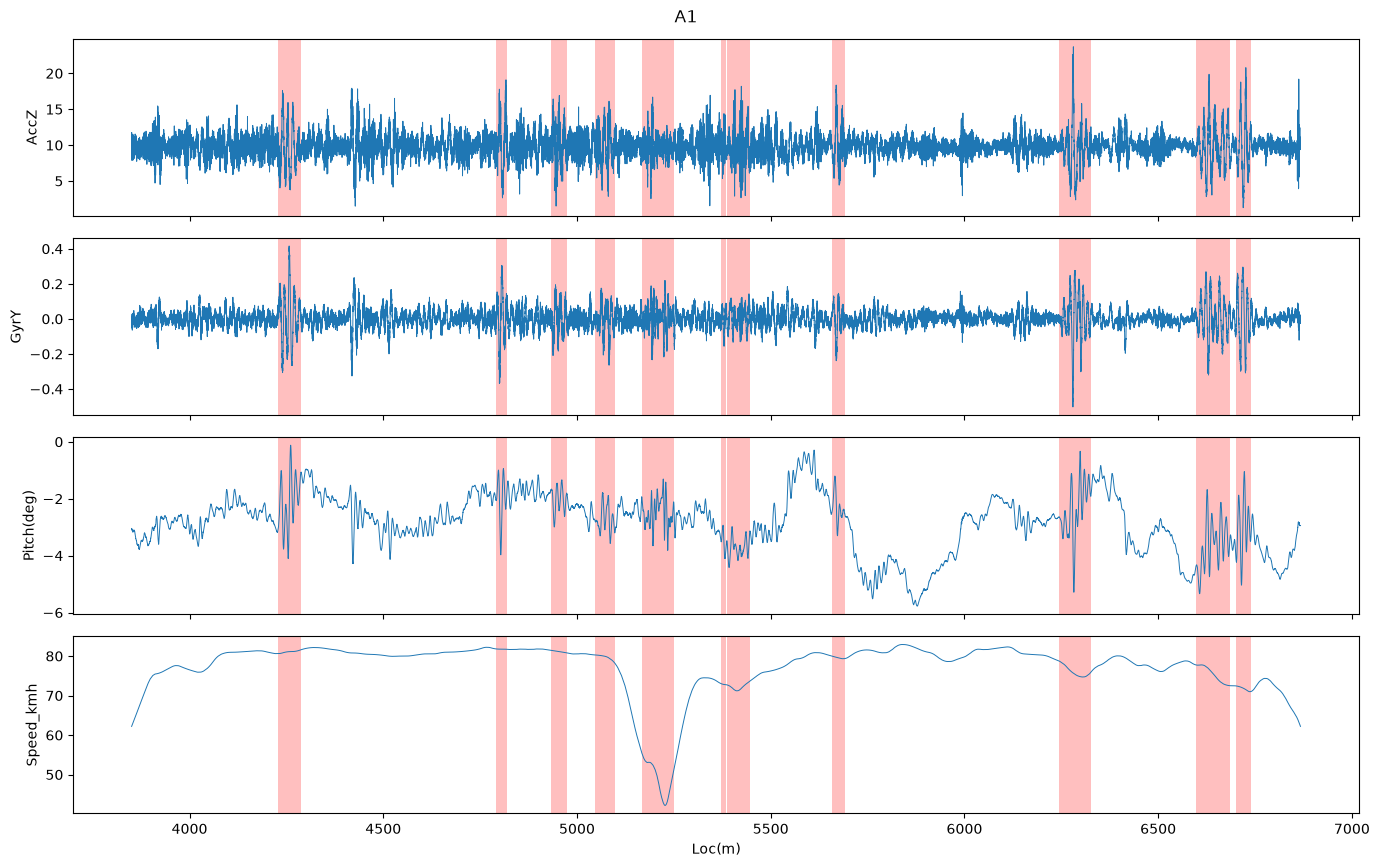

In [59]:


def plot_run(d, feats=("AccZ", "GyrY", "Pitch(deg)", "Speed_kmh"),
             x="Loc(m)", title=None, xlim=None):
    fig, axes = plt.subplots(len(feats), 1, figsize=(14, 2.2 * len(feats)),
                             sharex=True)
    for ax, f in zip(axes, feats):
        ax.plot(d[x], d[f], lw=0.7)
        ax.set_ylabel(f)

        # shade flagged bump regions
        flag = d["Frostbumps"].to_numpy() == 1
        edges = np.diff(flag.astype(int), prepend=0, append=0)
        starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0] - 1
        for s, e in zip(starts, ends):
            ax.axvspan(d[x].iloc[s], d[x].iloc[e], color="red", alpha=0.25, lw=0)

    axes[-1].set_xlabel(x)
    if xlim: axes[-1].set_xlim(xlim)
    fig.suptitle(title or "")
    fig.tight_layout()
    return fig

import numpy as np
plot_run(df[df.run_id == "A1"], title="A1")

In [60]:
feats = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
         "Pitch(deg)", "Roll(deg)", "Speed_kmh"]

stats = df.groupby("Frostbumps")[feats].agg(["mean", "std", "min", "median", "max"])
print(stats.T)   # transposed is easier to read

Frostbumps                 0          1
AccX       mean     0.487872   0.357972
           std      0.713628   0.684575
           min     -5.397300  -3.384420
           median   0.494990   0.361080
           max      4.705250   4.918070
AccY       mean     0.304453   0.253037
           std      0.493846   0.681164
           min     -6.279020  -5.163600
           median   0.303375   0.260590
           max      4.577280   5.064190
AccZ       mean     9.825268   9.803714
           std      0.920843   1.837253
           min      1.498380   1.286240
           median   9.819005   9.809010
           max     19.194780  23.703130
GyrX       mean    -0.004235  -0.007977
           std      0.027587   0.057836
           min     -0.222410  -0.408610
           median  -0.003750  -0.006230
           max      0.185740   0.491990
GyrY       mean     0.000412   0.002763
           std      0.032652   0.087170
           min     -0.325800  -0.502450
           median   0.000460   0.001120


<Axes: >

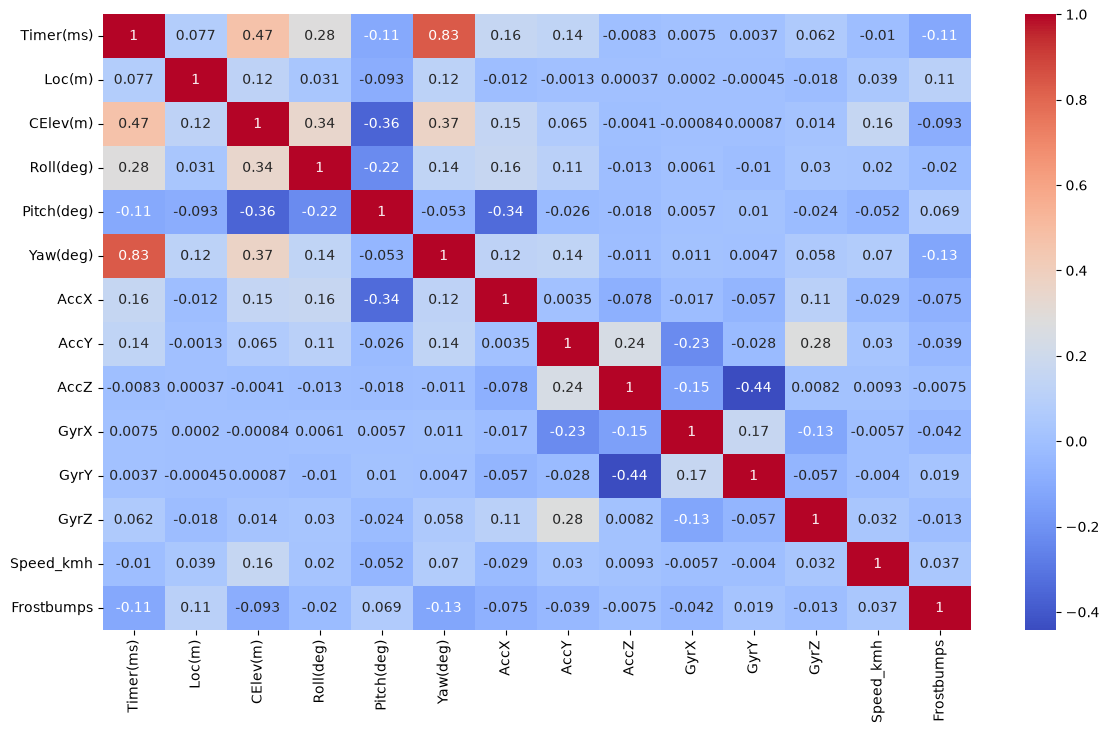

In [61]:
correlatinos = df.corr(numeric_only=True)
plt.figure(figsize=(14,8))
sns.heatmap(correlatinos, annot=True, cmap='coolwarm')

interval columns not set, guessing: ['Timer(ms)', 'Loc(m)', 'CElev(m)', 'Roll(deg)', 'Pitch(deg)', 'Yaw(deg)', 'AccX', 'AccY', 'AccZ', 'GyrX', 'GyrY', 'GyrZ', 'Speed_kmh', 'Frostbumps']


<Axes: >

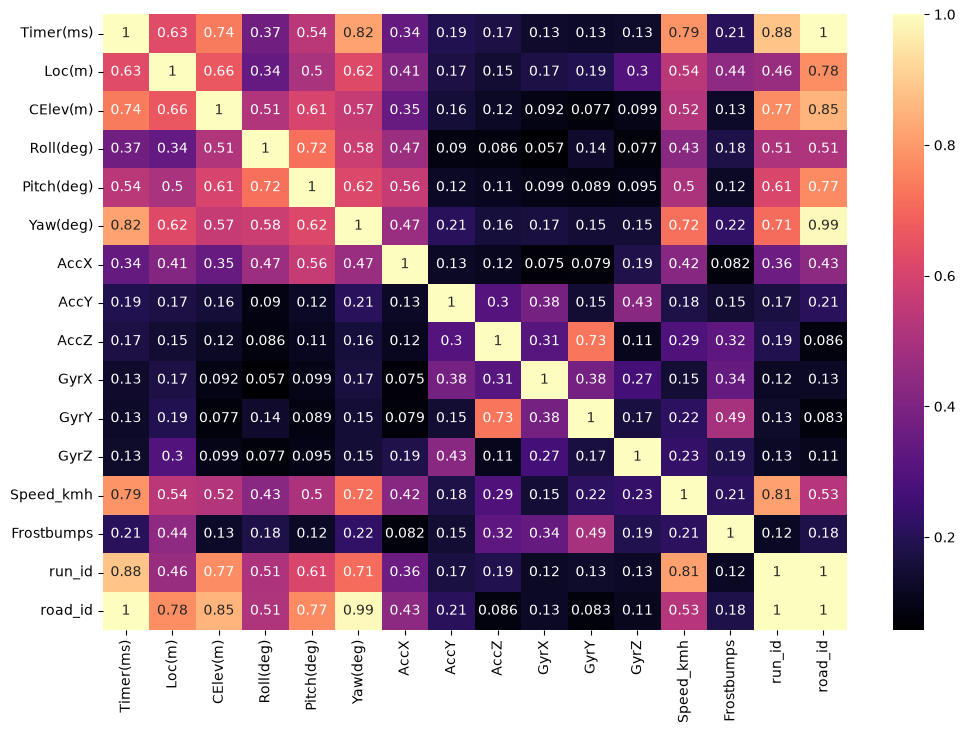

In [62]:
import phik

phik_matrix = df.phik_matrix()

plt.figure(figsize=(12,8))

sns.heatmap(phik_matrix, annot=True, cmap='magma')

In [63]:
# feats = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
#          "Pitch(deg)", "Roll(deg)", "Speed_kmh"]

# stats = dfC1.groupby("Frostbumps")[feats].agg(["mean", "std", "min", "median", "max"])
# print(stats.T)   # transposed is easier to read

In [64]:
for f in ["AccZ", "GyrY"]:
    df[f + "_abs"] = df[f].abs()

print(df.groupby("Frostbumps")[["AccZ_abs", "GyrY_abs"]].describe().T)

Frostbumps                  0             1
AccZ_abs count  235956.000000  64861.000000
         mean        9.825268      9.803714
         std         0.920843      1.837253
         min         1.498380      1.286240
         25%         9.388190      8.978610
         50%         9.819005      9.809010
         75%        10.254788     10.551930
         max        19.194780     23.703130
GyrY_abs count  235956.000000  64861.000000
         mean        0.022607      0.060882
         std         0.023563      0.062447
         min         0.000000      0.000000
         25%         0.006990      0.016740
         50%         0.015620      0.039980
         75%         0.030150      0.083890
         max         0.325800      0.502450


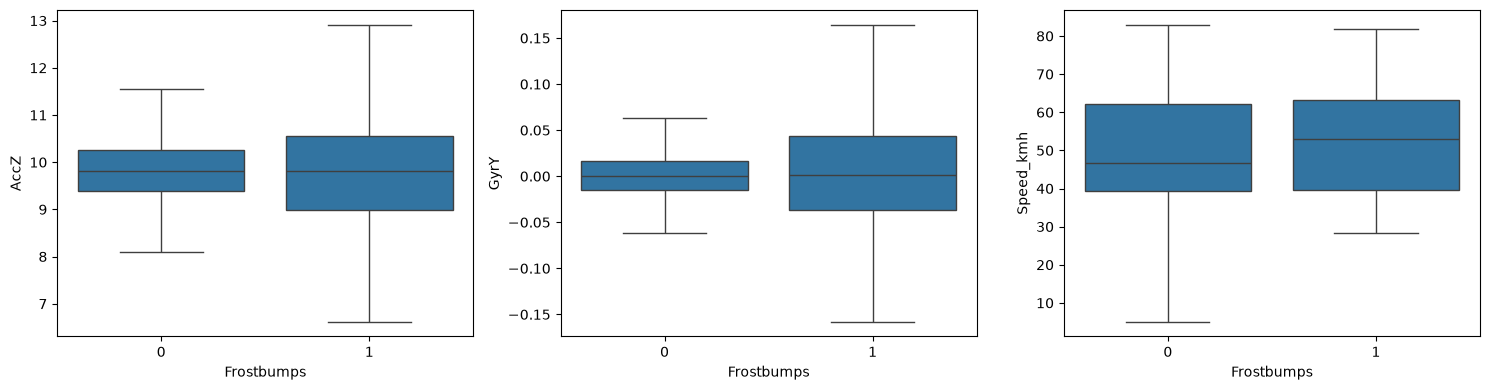

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, f in zip(axes, ["AccZ", "GyrY", "Speed_kmh"]):
    sns.boxplot(data=df, x="Frostbumps", y=f, ax=ax, showfliers=False)
plt.tight_layout()

In [66]:
def bump_events(d):
    flag = d["Frostbumps"].to_numpy()
    edges = np.diff(flag, prepend=0, append=0)
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0]
    rows = []
    for s, e in zip(starts, ends):
        seg = d.iloc[s:e]
        rows.append({
            "run_id": d["run_id"].iloc[0],
            "n_rows": len(seg),
            "length_m": seg["Loc(m)"].iloc[-1] - seg["Loc(m)"].iloc[0],
            "speed": seg["Speed_kmh"].mean(),
            "accz_peak": seg["AccZ"].abs().max(),
            "gyry_peak": seg["GyrY"].abs().max(),
            "accz_rms": np.sqrt((seg["AccZ"]**2).mean()),
        })
    return pd.DataFrame(rows)

events = pd.concat([bump_events(d) for _, d in df.groupby("run_id")], ignore_index=True)
print(events.describe())

           n_rows    length_m      speed  accz_peak  gyry_peak   accz_rms
count    41.00000   41.000000  41.000000  41.000000  41.000000  41.000000
mean   1581.97561   59.108073  58.229414  16.068481   0.269712  10.024913
std     879.63761   27.790863  15.792591   2.643295   0.094508   0.215520
min     256.00000   12.928000  37.877312  11.878940   0.101250   9.789354
25%     941.00000   36.977000  39.763797  13.863440   0.198450   9.872013
50%    1462.00000   57.975000  59.523944  16.065470   0.260020   9.968377
75%    2197.00000   81.973000  72.144498  17.605220   0.320760  10.079467
max    3933.00000  112.976000  81.753203  23.703130   0.502450  10.744820


In [67]:
feature_cols = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
                "Pitch(deg)", "Roll(deg)", "Speed_kmh"]


In [68]:
# run_df = df[df["run_id"] == "A1"]
# win = 400
# stride = 80

# run_df = run_df.sort_values("Timer(ms)")
# print(run_df.shape)

# X = run_df[feature_cols].to_numpy(np.float32)
# y = run_df["Frostbumps"].to_numpy()
# print(X.shape, y.shape)
# print(X[:3])
# print(y[:20])

# starts = list(range(0, len(X) - win + 1, stride))
# print(len(starts), starts[:5], starts[-1])

# start = 0
# end = start + win
# clip = X[start:end]
# print(clip.shape)
# print(y[start:end].max())

# X_clips, y_clips = [], []
# for start in range(0, len(X) - win + 1, stride):
#     end = start + win
#     X_clips.append(X[start:end])
#     y_clips.append(y[start:end].max())

# X_clips = np.array(X_clips)
# y_clips = np.array(y_clips)
# print(X_clips.shape, y_clips.shape, y_clips.mean())

In [69]:
def make_row_windows(run_df, win=100, stride=20):
    run_df = run_df.sort_values("Timer(ms)")
    X = run_df[feature_cols].to_numpy(np.float32)
    y = run_df["Frostbumps"].to_numpy()

    X_clips, y_clips = [], []
    for start in range(0, len(X) - win + 1, stride):
        end = start + win
        X_clips.append(X[start:end])
        y_clips.append(y[start:end].max())

    return np.array(X_clips), np.array(y_clips)

In [70]:
def get_clips(run_names):
    all_X, all_y = [], []
    for name in run_names:
        one_run = df[df["run_id"] == name]
        X, y = make_row_windows(one_run, win=400, stride=80)
        all_X.append(X)
        all_y.append(y)
    return np.concatenate(all_X), np.concatenate(all_y)

In [71]:
# Training, validation, test splits

Xtr, ytr = get_clips(["A1", "A2", "B1", "B2", "B3"])
Xva, yva = get_clips(["A3"])
Xte, yte = get_clips(["B4"])

print(Xtr.shape, Xva.shape, Xte.shape)
print(ytr.mean(), yva.mean(), yte.mean())

(2077, 400, 9) (1429, 400, 9) (222, 400, 9)
0.2855079441502167 0.22043386983904828 0.38738738738738737


In [72]:
from sklearn.preprocessing import StandardScaler

n_features = Xtr.shape[-1]      # 9 now

scaler = StandardScaler()
scaler.fit(Xtr.reshape(-1, n_features))

Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=Xtr.shape[1:]),
    layers.Conv1D(32, 7, padding="same", activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 5, padding="same", activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, padding="same", activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(optimizer="adam", loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])

w = min((ytr == 0).sum() / max((ytr == 1).sum(), 1), 20)

model.fit(Xtr, ytr, validation_data=(Xva, yva),
          epochs=100, batch_size=32,
          class_weight={0: 1.0, 1: float(w)},
          callbacks=[keras.callbacks.EarlyStopping(
              monitor="val_loss", patience=10, restore_best_weights=True)])

from sklearn.metrics import average_precision_score
probs = model.predict(Xte).ravel()
print("Test PR-AUC:", average_precision_score(yte, probs))

Epoch 1/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.8116 - pr_auc: 0.6551 - val_loss: 0.4664 - val_pr_auc: 0.6354
Epoch 2/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6418 - pr_auc: 0.7785 - val_loss: 0.3925 - val_pr_auc: 0.6577
Epoch 3/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5428 - pr_auc: 0.8359 - val_loss: 0.4160 - val_pr_auc: 0.6531
Epoch 4/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4781 - pr_auc: 0.8705 - val_loss: 0.4017 - val_pr_auc: 0.6624
Epoch 5/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4201 - pr_auc: 0.8958 - val_loss: 0.4510 - val_pr_auc: 0.6196
Epoch 6/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3690 - pr_auc: 0.9225 - val_loss: 0.4062 - val_pr_auc: 0.6480
Epoch 7/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3373 - pr_auc: 0.9355 - val_loss: 0.4952 - val_pr_auc: 0.6349
Epoch 8/100
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2803 - pr_auc: 0.9538 - val_loss: 0.4557 - val_pr_auc: 0.6575
Epoch 9/100
65/6

In [84]:
print("Score:", average_precision_score(yte, probs))
print("Random guess:", yte.mean())

Score: 0.6297018762837552
Random guess: 0.38738738738738737


<Axes: >

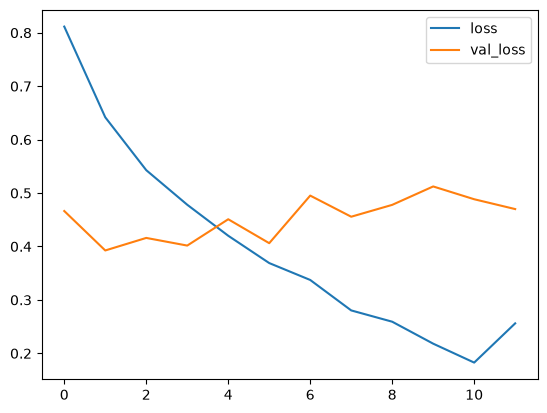

In [88]:
loss_df = pd.DataFrame(model.history.history)
loss_df[['loss', 'val_loss']].plot()